# Cavity haloscopes

In cavity haloscope experiments, a cavity in a static magnetic field converts an axion signal into resonant microwave power. In this tutorial we follow a cylindrical cavity through mode solving, tuning and receiver sensitivity. The modes are axisymmetric, with no azimuthal variation. The cavity and haloscope modules are beta.

## Form factor

The dimensionless form factor measures electric-field overlap with the static field:

$$
C=\frac{\left|\int_V \mathbf E\cdot\mathbf B_0\,dV\right|^2}{B_{\rm ref}^2 V\int_V\varepsilon_r|\mathbf E|^2\,dV}.
$$

Here $\varepsilon_r$ is relative permittivity. The volume $V$ excludes conductors and includes dielectrics; $B_{\rm ref}$ is the cavity's rms static field here.

We import the libraries and prepare a run directory and plotting settings for the cavity calculations.

In [1]:
import math, sys, tempfile, warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.special import j0, y0, jn_zeros

try:
    import axionfem as af
except ImportError:                       # running from a source checkout without installing
    sys.path.insert(0, str(Path.cwd().parent / "python"))
    import axionfem as af

from axionfem import cavity as cv, haloscope as hs

print("axionFEM", af.__version__)
RUNS = Path(tempfile.mkdtemp(prefix="axf_cavity_demo_"))   # solver run directories
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True, "grid.color": "#e4e3df",
                     "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
                     "lines.linewidth": 1.8, "legend.frameon": False})
# fixed categorical order
BLUE, ORANGE, GREEN, GOLD, VIOLET, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#6f6e69"
CHI0 = jn_zeros(0, 3)                      # zeros of J0: 2.405, 5.520, 8.654

axionFEM 0.1.0


## Empty copper cylinder

For uniform wall resistance and no dielectric loss, the intrinsic quality factor is

$$
Q_0 = \frac{G}{R_s}, \qquad
G = \frac{\omega\int_V \mu |\mathbf H|^2\,dV}
{\oint_{\partial V}|\mathbf H_t|^2\,dA}.
$$

Here $\omega$ is angular frequency, $\mu$ is permeability and $\mathbf H_t$ is the tangential wall field. The geometry factor $G$ and surface resistance $R_s$ are in ohms. Losses are evaluated on the lossless mode, assuming small losses.

In the classical skin regime (mean free path much smaller than skin depth), resistivity $\rho$ at the operating temperature gives

$$
R_s = \sqrt{\pi f\mu_0\rho}.
$$

Here $f$ is frequency and $\mu_0$ is vacuum permeability. The cold-copper example uses an anomalous-skin model. `surface_resistance` evaluates the chosen model at frequency $f$. These ideal surfaces omit joints, roughness and magnetic-field effects; predictions should use resistance measured at the operating field.

We define the copper model and cylinder dimensions and compare surface resistances for the loss calculation.

In [2]:
RHO300 = 1.725e-8                                # copper at 300 K [ohm m] (CRC)
CU_RF = {"model": "anomalous", "RRR": 100, "rho_300K_ohm_m": RHO300, "rho_l_ohm_m2": 6.6e-16,
         "specularity": 0.0, "T_K": 0.15}
CU = {"kind": "conductor", "rf": CU_RF}          # perfect at RF for the field solve; R_s enters perturbatively

F0 = 650e6
A = CHI0[0] * cv.C_LIGHT / (2 * math.pi * F0)    # radius for TM010 at 650 MHz
L = A / 0.21                                     # ADMX-like aspect ratio (21 cm x 1 m)
print(f"a = {A*100:.2f} cm, L = {L*100:.1f} cm, V = {math.pi*A*A*L*1e3:.1f} L")
print(f"R_s(650 MHz): anomalous RRR 100 {cv.surface_resistance(CU_RF, F0)*1e3:.3f} mOhm, "
      f"extreme-anomalous limit {cv.surface_resistance(dict(CU_RF, RRR=1e6), F0)*1e3:.3f} mOhm, "
      f"300 K skin {cv.skin_Rs(F0, RHO300)*1e3:.3f} mOhm")

a = 17.65 cm, L = 84.1 cm, V = 82.3 L
R_s(650 MHz): anomalous RRR 100 1.042 mOhm, extreme-anomalous limit 0.843 mOhm, 300 K skin 6.653 mOhm


### Geometry and mode solve

`pillbox_design` returns a `Design`; `solve` returns modes and diagnostics.

We build and solve the empty cylinder to obtain its modes and diagnostics.

In [3]:
d = cv.pillbox_design(A, L, h=0.03, modes=8, wall_material=CU, Bz=1.0)
print({k: d.doc[k] for k in ("background", "fullwave", "cavity")})
res = d.solve(RUNS / "pillbox", verbose=0)
print(f"{res.data['mesh']['dofs']} DOFs")
cav = res.data["fullwave"]["cavity"]
print(f"cavity regions {cav['regions']}, V = {cav['volume_m3']*1e3:.2f} L, B_ref = {cav['B_ref']} = {cav['B_ref_T']} T")

{'background': {'type': 'uniform', 'Bz': 1.0}, 'fullwave': {'modes': 8, 'families': ['TE', 'TM'], 'boundary': 'pec'}, 'cavity': {'interior_point': [np.float64(0.08826348295016158), 0.0]}}
7363 DOFs
cavity regions ['cavity'], V = 82.29 L, B_ref = volume rms of B0 over the cavity = 1.0 T


### Mode properties

`cavity_modes` lists frequency, form factor and losses. We tabulate the mode properties alongside analytic cylinder values to check the solve.

In [4]:
modes = res.cavity_modes()
ref = cv.pillbox_modes(A, L, 1.4e9)
print(f"{'mode':8s}{'f [MHz]':>11s}{'f/f_exact-1':>13s}{'C':>10s}{'C exact':>9s}{'G [ohm]':>9s}"
      f"{'G/G_exact-1':>13s}{'Q0':>10s}{'Q0 (300 K)':>12s}")
for m in modes[:10]:
    x = min((q for q in ref if q["family"] == m["family"]), key=lambda q: abs(q["f_Hz"] - m["f_Hz"]))
    name = f"{m['family']}0{x['n']}{x['p']}"
    Q300 = m["G_ohm"] / cv.skin_Rs(m["f_Hz"], RHO300)
    print(f"{name:8s}{m['f_Hz']/1e6:11.4f}{m['f_Hz']/x['f_Hz']-1:13.1e}{m['C']:10.2e}{x['C']:9.4f}"
          f"{m['G_ohm']:9.2f}{m['G_ohm']/x['G_ohm']-1:13.1e}{m['Q0']:10.3g}{Q300:12.3g}")
tm010 = modes[0]

mode        f [MHz]  f/f_exact-1         C  C exact  G [ohm]  G/G_exact-1        Q0  Q0 (300 K)
TM010      650.0002      3.8e-07  6.92e-01   0.6917   374.37     -1.4e-06  3.59e+05    5.63e+04
TM011      674.0167      7.0e-07  3.25e-14   0.0000   330.79     -1.9e-06  3.11e+05    4.88e+04
TM012      741.4130      1.7e-06  8.73e-15   0.0000   363.86     -5.2e-06  3.22e+05    5.12e+04
TM013      841.8349      3.7e-06  5.89e-15   0.0000   413.14     -1.2e-05  3.38e+05    5.46e+04
TM014      965.0287      7.9e-06  4.69e-16   0.0000   473.60     -2.4e-05  3.56e+05    5.84e+04
TE011     1050.9196      8.6e-06  0.00e+00   0.0000   744.77     -5.8e-05  5.32e+05     8.8e+04
TE012     1095.3685      1.1e-05  0.00e+00   0.0000   813.30     -7.7e-05  5.66e+05    9.42e+04
TM015     1103.3976      1.6e-05  5.85e-16   0.0000   541.49     -4.3e-05  3.75e+05    6.25e+04
TE013     1165.6919      1.5e-05  0.00e+00   0.0000   925.29     -1.2e-04  6.19e+05    1.04e+05
TM016     1251.9271      3.1e-05  2.58e-

The fundamental TM mode couples strongly to the axial field; sign changes suppress higher-mode overlap. Mesh convergence, including $G$, should be checked before using $Q_0$.

### Mode fields

The electric-field maps and radial samples expose cancellations in higher modes.

We plot the fields and compare radial samples with analytic profiles to examine these cancellations.

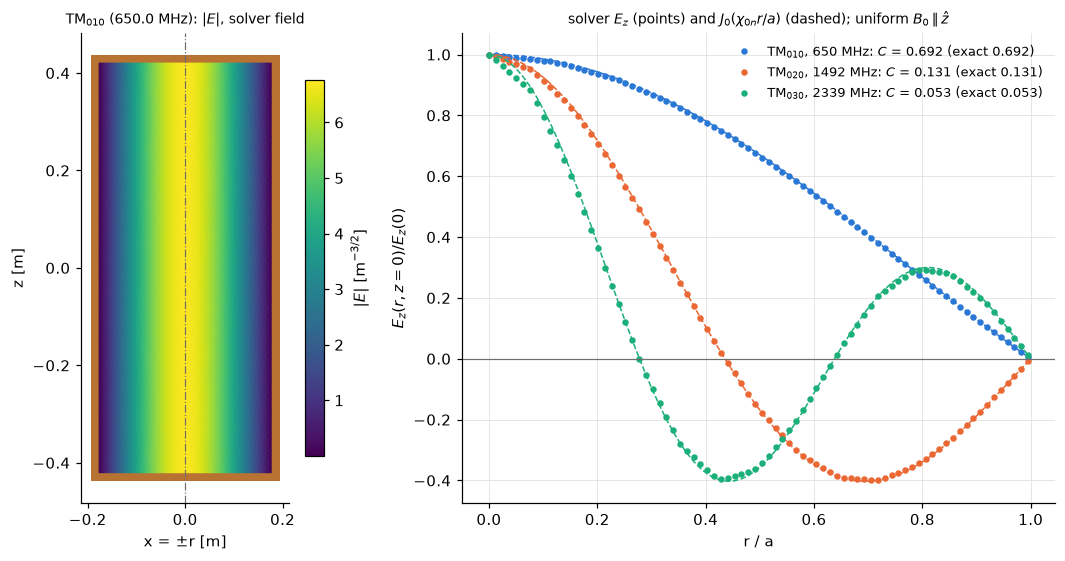

TM010: max |E_z/E_z(0) - J0(chi r/a)| = 6.7e-03
TM020: max |E_z/E_z(0) - J0(chi r/a)| = 1.4e-02
TM030: max |E_z/E_z(0) - J0(chi r/a)| = 3.1e-02


In [5]:
def draw_design(ax, design, colors=None, title="", mirror=False):
    # draw the rect / union-of-rect regions of an axisymmetric design in the (r, z) half-plane (both halves: mirror)
    colors = colors or {}
    def rects(shape):
        if "rect" in shape:
            yield shape["rect"]
        for s in shape.get("union", []):
            yield from rects(s)
    for reg in design.doc["regions"]:
        c = colors.get(reg["name"], "#b87333" if reg["name"] == "wall" else "#d6e6f5")
        for rc in rects(reg["shape"]):
            (r0, r1), (z0, z1) = rc["r"], rc["z"]
            for sgn in ((1, -1) if mirror else (1,)):
                lo, hi = sorted((sgn * r0, sgn * r1))
                ax.add_patch(plt.Rectangle((lo, z0), hi - lo, z1 - z0, fc=c, ec="none"))
    ax.axvline(0, color=GREY, lw=0.8, ls="-.")
    ax.set_aspect("equal"); ax.autoscale_view(); ax.grid(False)
    ax.set_xlabel("x = ±r [m]" if mirror else "r [m]"); ax.set_ylabel("z [m]"); ax.set_title(title, fontsize=9)

import matplotlib.tri as mtri

# TM020, TM030: targeted solves; the coupled mode is the one with the largest C among those returned
f0n0 = [cv.C_LIGHT * x / (2 * math.pi * A) for x in CHI0]
sols = [(res, tm010)]
for n in (1, 2):
    rn = cv.pillbox_design(A, L, h=0.015, modes=4, families=("TM",), wall_material=CU,
                           target_f_Hz=f0n0[n]).solve(RUNS / f"pillbox_tm0{n + 1}0", verbose=0)
    sols.append((rn, max(rn.cavity_modes(), key=lambda q: q["C"] or 0.0)))

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 5.2), gridspec_kw={"width_ratios": [1, 1.9]})
F = res.cavity_mode_field(tm010)                  # E, H on the cavity mesh (normalized to int |E|^2 dV = 1)
draw_design(ax0, d, mirror=True, title=f"TM$_{{010}}$ ({tm010['f_Hz']/1e6:.1f} MHz): $|E|$, solver field")
for sgn in (1, -1):
    tpc = ax0.tripcolor(mtri.Triangulation(sgn * F["r"], F["z"], F["tris"]), F["Emag"], shading="gouraud",
                        cmap="viridis", rasterized=True)
fig.colorbar(tpc, ax=ax0, shrink=0.8, label=r"$|E|$ [m$^{-3/2}$]")
r = np.linspace(0.0, 0.995 * A, 80)
for (rn, m), n, col in zip(sols, range(3), (BLUE, ORANGE, GREEN)):
    P = rn.cavity_mode_sample(m, r, np.zeros_like(r))
    ax1.plot(r / A, j0(CHI0[n] * r / A), color=col, lw=1.0, ls="--")
    ax1.plot(r / A, P["E_z"] / P["E_z"][0], "o", ms=3.2, color=col,
             label=f"TM$_{{0{n+1}0}}$, {m['f_Hz']/1e6:.0f} MHz: $C$ = {m['C']:.3f} (exact {4/CHI0[n]**2:.3f})")
ax1.axhline(0, color=GREY, lw=0.8)
ax1.set_xlabel("r / a"); ax1.set_ylabel(r"$E_z(r, z=0)/E_z(0)$")
ax1.set_title(r"solver $E_z$ (points) and $J_0(\chi_{0n}r/a)$ (dashed); uniform $B_0\parallel\hat z$", fontsize=9)
ax1.legend(fontsize=8.5, loc="upper right")
fig.tight_layout(); plt.show()
for (rn, m), n in zip(sols, range(3)):
    ez = rn.cavity_mode_sample(m, r, 0 * r)["E_z"]
    print(f"TM0{n + 1}0: max |E_z/E_z(0) - J0(chi r/a)| = {np.max(np.abs(ez / ez[0] - j0(CHI0[n] * r / A))):.1e}")

## Tuning with a centred rod

Increasing rod radius raises the coupled frequency. `target_f_Hz` selects nearby modes; we refine metal surfaces to resolve thin rods.

We sweep the rod radius to compare the coupled mode's properties with analytic coaxial values.

In [6]:
B_OUT = A                                    # same outer radius and length as the pillbox
ratios = np.array([0.05, 0.08, 0.12, 0.17, 0.23, 0.30, 0.38, 0.46])
sweep = []
for x in ratios:
    a_rod = x * B_OUT
    exact = cv.coax_tm_mode(a_rod, B_OUT)
    dc = cv.coax_design(a_rod, B_OUT, L, h=0.02, modes=4, target_f_Hz=exact["f_Hz"], wall_material=CU)
    dc.doc["mesh"]["surface_size"] = min(0.02, a_rod / 4)
    rc = dc.solve(RUNS / f"coax_{x:.2f}", verbose=0)
    rows = rc.cavity_modes()
    best = max(rows, key=lambda q: q["C"] or 0.0)      # the axion-coupled mode = largest C
    sweep.append({"x": x, "a": a_rod, "exact": exact, "best": best, "all": rows})
print(f"{len(ratios)} solves")
print(f"{'a/b':>5s}{'f [MHz]':>10s}{'rel err':>10s}{'C':>8s}{'C exact':>9s}{'V [L]':>8s}{'G [ohm]':>9s}{'Q0':>10s}")
for s in sweep:
    b_, e = s["best"], s["exact"]
    print(f"{s['x']:5.2f}{b_['f_Hz']/1e6:10.2f}{b_['f_Hz']/e['f_Hz']-1:10.1e}{b_['C']:8.4f}{float(e['C']):9.4f}"
          f"{b_['V_m3']*1e3:8.1f}{b_['G_ohm']:9.1f}{b_['Q0']:10.3g}")

8 solves
  a/b   f [MHz]   rel err       C  C exact   V [L]  G [ohm]        Q0
 0.05    828.39   1.3e-04  0.7635   0.7637    82.1    190.2  1.57e+05
 0.08    869.46   5.6e-05  0.7721   0.7722    81.8    212.0   1.7e+05
 0.12    921.94   2.5e-05  0.7801   0.7802    81.1    229.1  1.77e+05
 0.17    989.00   9.8e-06  0.7873   0.7873    79.9    242.3   1.8e+05
 0.23   1076.18   4.6e-06  0.7933   0.7933    77.9    252.8  1.78e+05
 0.30   1192.63   5.7e-06  0.7983   0.7983    74.9    261.3  1.72e+05
 0.38   1354.26   1.6e-05  0.8024   0.8023    70.4    268.4  1.64e+05
 0.46   1560.97   3.8e-05  0.8052   0.8051    64.9    273.8  1.53e+05


We plot frequency, form factor and $Q_0$ against rod radius to show the tuning tradeoffs.

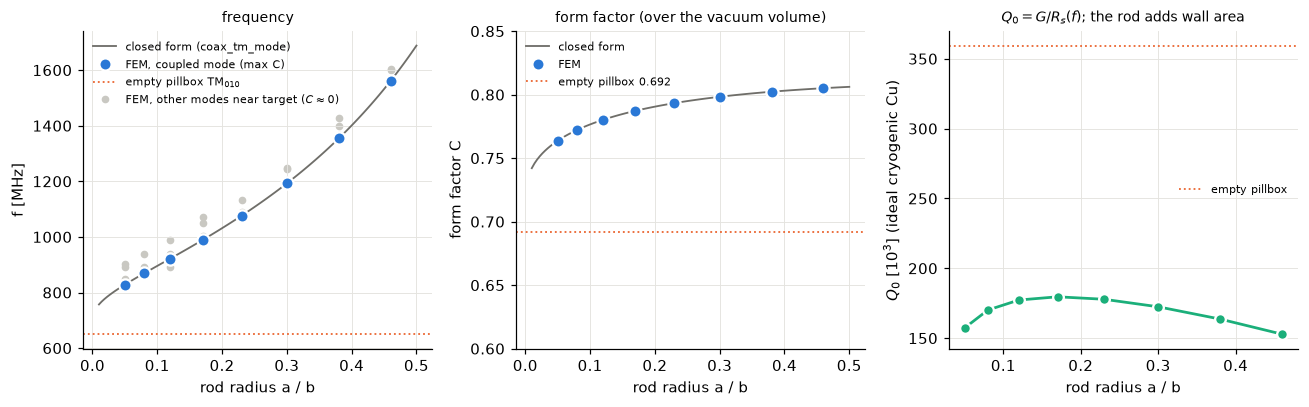

In [7]:
xs = np.linspace(0.01, 0.5, 120)
cf = [cv.coax_tm_mode(x * B_OUT, B_OUT) for x in xs]
fig, axs = plt.subplots(1, 3, figsize=(12, 3.8))
ax = axs[0]
for s in sweep:                                   # every mode the targeted solve returned (grey), coupled one coloured
    for q in s["all"]:
        ax.plot(s["x"], q["f_Hz"] / 1e6, "o", ms=4, color="#c9c8c2", zorder=1)
ax.plot(xs, [c["f_Hz"] / 1e6 for c in cf], color=GREY, lw=1.2, label="closed form (coax_tm_mode)")
ax.plot(ratios, [s["best"]["f_Hz"] / 1e6 for s in sweep], "o", ms=8, color=BLUE, mec="white", mew=1.5,
        label="FEM, coupled mode (max C)", zorder=3)
ax.axhline(F0 / 1e6, color=ORANGE, ls=":", lw=1.2, label="empty pillbox TM$_{010}$")
ax.plot([], [], "o", ms=4, color="#c9c8c2", label="FEM, other modes near target ($C\\approx0$)")
ax.set_xlabel("rod radius a / b"); ax.set_ylabel("f [MHz]"); ax.legend(fontsize=7.5); ax.set_title("frequency", fontsize=9)
ax = axs[1]
ax.plot(xs, [float(c["C"]) for c in cf], color=GREY, lw=1.2, label="closed form")
ax.plot(ratios, [s["best"]["C"] for s in sweep], "o", ms=8, color=BLUE, mec="white", mew=1.5, label="FEM")
ax.axhline(4 / CHI0[0] ** 2, color=ORANGE, ls=":", lw=1.2, label="empty pillbox 0.692")
ax.set_xlabel("rod radius a / b"); ax.set_ylabel("form factor C"); ax.set_ylim(0.6, 0.85)
ax.legend(fontsize=7.5); ax.set_title("form factor (over the vacuum volume)", fontsize=9)
ax = axs[2]
ax.plot(ratios, [s["best"]["Q0"] / 1e3 for s in sweep], "o-", ms=7, color=GREEN, mec="white", mew=1.5)
ax.axhline(tm010["Q0"] / 1e3, color=ORANGE, ls=":", lw=1.2, label="empty pillbox")
ax.set_xlabel("rod radius a / b"); ax.set_ylabel(r"$Q_0$ [$10^3$] (ideal cryogenic Cu)")
ax.legend(fontsize=7.5); ax.set_title(r"$Q_0=G/R_s(f)$; the rod adds wall area", fontsize=9)
fig.tight_layout(); plt.show()

The rod changes usable volume and wall losses.

### Dielectric sleeve

The sleeve lowers frequency and adds dielectric loss, reducing $Q_0$. Its position controls the electric-energy fraction in sapphire.

We vary the sleeve position to compare mode properties and losses with analytic values.

In [8]:
EPS, TAND, W = 9.4, 1e-5, 0.01
def sleeve_design(r1):
    ds = cv.pillbox_design(A, L, h=0.03, modes=2, families=("TM",), wall_material=CU)
    ds.doc["materials"]["sapphire"] = {"kind": "linear", "eps_r": EPS, "tan_delta": TAND}
    ds.doc["regions"].insert(1, {"name": "sleeve", "shape": {"rect": {"r": [r1, r1 + W], "z": [-L / 2, L / 2]}},
                                 "material": "sapphire", "mesh_size": 0.0025})
    return ds

r1s = np.array([0.0, 0.03, 0.06, 0.09, 0.12, A - W])
sl = []
for r1 in r1s:
    m = sleeve_design(r1).solve(RUNS / f"sleeve_{r1:.3f}", verbose=0).cavity_modes()[0]
    sl.append((r1, m, cv.sleeve_tm_mode(A, r1, r1 + W, EPS)))
print(f"{'sleeve r [cm]':>14s}{'f [MHz]':>10s}{'rel err':>10s}{'C':>8s}{'C exact':>9s}{'Q_d':>10s}{'1/(tand fe)':>12s}{'Q_wall':>9s}{'Q0':>9s}")
for r1, m, e in sl:
    print(f"{r1*100:6.1f}-{(r1+W)*100:<7.1f}{m['f_Hz']/1e6:10.2f}{m['f_Hz']/e['f_Hz']-1:10.1e}{m['C']:8.4f}{e['C']:9.4f}"
          f"{m['Q_dielectric']:10.3g}{1/(TAND*e['fe_sleeve']):12.3g}{m['Q_wall']:9.3g}{m['Q0']:9.3g}")

 sleeve r [cm]   f [MHz]   rel err       C  C exact       Q_d 1/(tand fe)   Q_wall       Q0
   0.0-1.0        615.87   8.2e-04  0.5951   0.5936  7.77e+05    7.54e+05 3.88e+05 2.59e+05
   3.0-4.0        494.24   6.0e-05  0.3421   0.3420  1.95e+05    1.95e+05 4.57e+05 1.37e+05
   6.0-7.0        468.85   5.9e-06  0.3323   0.3323   1.8e+05     1.8e+05 4.02e+05 1.24e+05
   9.0-10.0       483.15   5.1e-07  0.3761   0.3761   1.9e+05     1.9e+05 3.28e+05  1.2e+05
  12.0-13.0       533.42   1.2e-07  0.4736   0.4736  2.41e+05    2.41e+05 2.54e+05 1.24e+05
  16.7-17.7       647.99   3.0e-07  0.6909   0.6909  1.36e+07    1.36e+07 3.17e+05  3.1e+05


We plot the sleeve geometry, frequency and form factor to compare the tuning results with analytic curves.

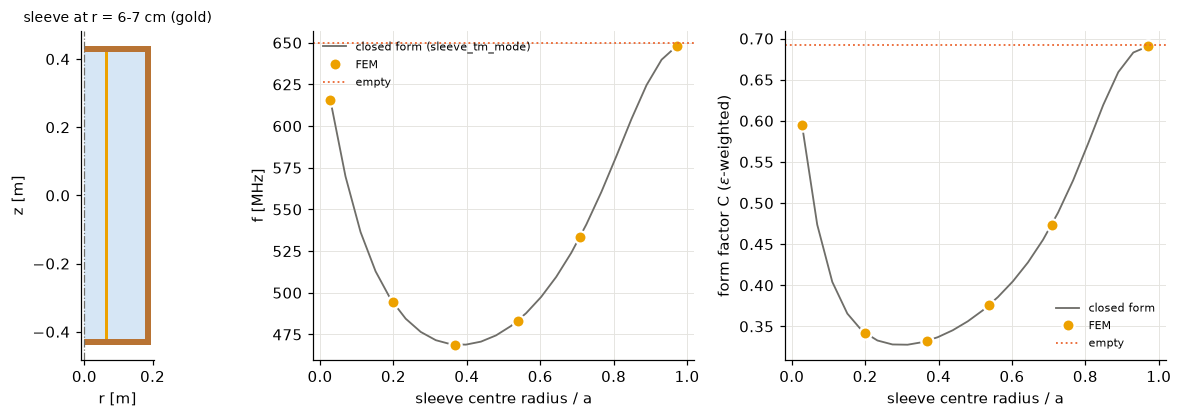

In [9]:
rc = np.linspace(0.0, A - W, 24)
ex = [cv.sleeve_tm_mode(A, r1, r1 + W, EPS) for r1 in rc]
fig, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(11, 3.9), gridspec_kw={"width_ratios": [0.55, 1, 1]})
draw_design(ax0, sleeve_design(0.06), colors={"sleeve": GOLD}, title="sleeve at r = 6-7 cm (gold)")
mid = lambda r1: (r1 + W / 2) / A
ax1.plot(mid(rc), [e["f_Hz"] / 1e6 for e in ex], color=GREY, lw=1.2, label="closed form (sleeve_tm_mode)")
ax1.plot([mid(r1) for r1, _, _ in sl], [m["f_Hz"] / 1e6 for _, m, _ in sl], "o", ms=8, color=GOLD, mec="white",
         mew=1.5, label="FEM")
ax1.axhline(F0 / 1e6, color=ORANGE, ls=":", lw=1.2, label="empty")
ax1.set_xlabel("sleeve centre radius / a"); ax1.set_ylabel("f [MHz]"); ax1.legend(fontsize=7.5)
ax2.plot(mid(rc), [e["C"] for e in ex], color=GREY, lw=1.2, label="closed form")
ax2.plot([mid(r1) for r1, _, _ in sl], [m["C"] for _, m, _ in sl], "o", ms=8, color=GOLD, mec="white", mew=1.5,
         label="FEM")
ax2.axhline(4 / CHI0[0] ** 2, color=ORANGE, ls=":", lw=1.2, label="empty")
ax2.set_xlabel("sleeve centre radius / a"); ax2.set_ylabel(r"form factor C ($\varepsilon$-weighted)")
ax2.legend(fontsize=7.5)
fig.tight_layout(); plt.show()

## Sensitivity from modes

We combine solved mode properties in `haloscope.Cavity` with a receiver preset.

### Signal power

We use the same rms field normalization for the magnet strength and form factor. We calculate power and photon rate for the solved mode and the ADMX 1A preset to compare their signals.

In [10]:
f1, C1, V1, Q01 = tm010["f_Hz"], tm010["C"], tm010["V_m3"], tm010["Q0"]
m_eV = float(hs.freq_to_mass_eV(f1))
gD, gK = float(hs.g_axion(m_eV, "DFSZ")), float(hs.g_axion(m_eV, "KSVZ"))
admx_cav, admx_rx, admx_an = hs.preset_models("ADMX_1A")
B_ADMX = admx_cav.B_T
print(f"f = {f1/1e6:.3f} MHz, m_a = {m_eV*1e6:.3f} ueV, g_DFSZ = {gD:.3e}, g_KSVZ = {gK:.3e} GeV^-1")
for lab, kw in [("FEM pillbox, beta = 2", dict(V_m3=V1, C=C1, Q0=Q01, beta=2.0)),
                ("ADMX 1A preset (136 L, C 0.4, Q_L 5e4, beta 1)", dict(V_m3=admx_cav.V_m3, C=admx_cav.C,
                                                                       Q0=admx_cav.Q0, beta=admx_cav.beta))]:
    P = hs.signal_power(gD, f1, B_ADMX, kw["V_m3"], kw["C"], Q0=kw["Q0"], beta=kw["beta"])
    print(f"  {lab:48s}: P_DFSZ = {P:.3e} W = {P/(hs.H_PLANCK*f1):.1f} photons/s")
print(f"  radiometer: SNR 5 at T_sys = 0.5 K in 100 s over b = f/Q_a = {f1/hs.Q_a_shm():.0f} Hz needs "
      f"P = {5*hs.KB*0.5*math.sqrt(f1/hs.Q_a_shm()/100):.2e} W")

f = 650.000 MHz, m_a = 2.688 ueV, g_DFSZ = 3.733e-16, g_KSVZ = 1.006e-15 GeV^-1
  FEM pillbox, beta = 2                           : P_DFSZ = 4.555e-23 W = 105.8 photons/s
  ADMX 1A preset (136 L, C 0.4, Q_L 5e4, beta 1)  : P_DFSZ = 1.363e-23 W = 31.6 photons/s
  radiometer: SNR 5 at T_sys = 0.5 K in 100 s over b = f/Q_a = 959 Hz needs P = 1.07e-22 W


### Antenna coupling

Port coupling $\beta$ broadens the resonance from intrinsic $Q_0$ to loaded $Q_L$. With noise-equivalent axion bandwidth $\Delta f_{\rm eff}$,

$$
Q_L=\frac{Q_0}{1+\beta},\qquad \Delta f_{\rm eff}=\frac{f}{Q_a}.
$$

Here $Q_a$ describes the noise-equivalent axion width, rather than its full width at half maximum. For optimal weighting, unit analysis efficiency, dense tuning steps and no dead time, the scan rate at target signal-to-noise ratio (SNR) is

$$
\frac{df}{dt}=\frac{1}{{\rm SNR}^2\,\Delta f_{\rm eff}}\int d\delta\left[\frac{P(\delta)}{hf\,N_{\rm sys}(\delta)}\right]^2.
$$

Here $h$ is Planck's constant and $P(\delta)$ is received monochromatic signal power at detuning $\delta$; $hfN_{\rm sys}$ is noise power per bandwidth. `scan_rate` returns Hz/s of live integration at the target coupling and SNR. The curves use optimal weighting and the binned estimator of Kim et al., arXiv:2001.05605, with their respective bandwidth conventions and normalizations.

We vary antenna coupling to compare scan rates and locate their optima.

beta_opt: optimal weighting 2.000;  Kim 2020 (Q_a,kim = 1e6) 2.223
scan rate at DFSZ, SNR 5, beta = 2: 7.74 Hz/s = 0.67 MHz/day (KSVZ: 35.3 MHz/day)


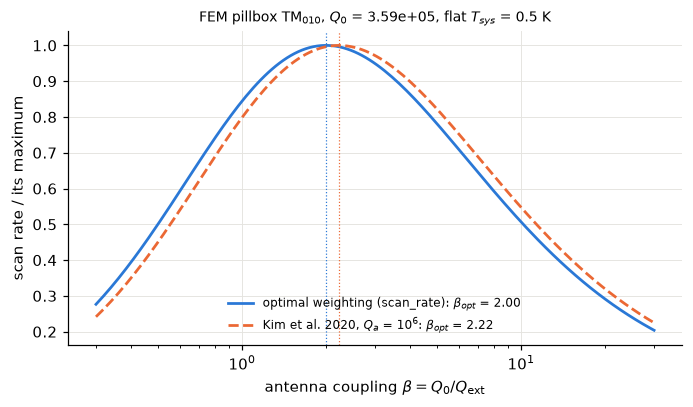

In [11]:
cav1 = hs.Cavity(B_T=B_ADMX, V_m3=V1, C=C1, Q0=Q01, beta=2.0, label="FEM pillbox")
betas = np.geomspace(0.3, 30, 150)
r_opt = np.array([hs.scan_rate(f1, hs.Cavity(B_ADMX, V1, C1, Q01, b), admx_rx, g_GeV=gD) for b in betas])
r_kim = np.array([hs.scan_rate_kim2020(f1, hs.Cavity(B_ADMX, V1, C1, Q01, b), g_GeV=gD, T_sys_K=0.5, Q_a_kim=1e6)
                  for b in betas])
b_opt = hs.beta_opt(f1, cav1, admx_rx, g_GeV=gD)
b_kim = hs.beta_opt_kim2020(Q01, 1e6)
rate1 = hs.scan_rate(f1, cav1, admx_rx, g_GeV=gD, snr=5.0)
print(f"beta_opt: optimal weighting {b_opt:.3f};  Kim 2020 (Q_a,kim = 1e6) {b_kim:.3f}")
print(f"scan rate at DFSZ, SNR 5, beta = 2: {rate1:.3g} Hz/s = {rate1*86400/1e6:.2f} MHz/day "
      f"(KSVZ: {hs.scan_rate(f1, cav1, admx_rx, g_GeV=gK, snr=5.0)*86400/1e6:.1f} MHz/day)")

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(betas, r_opt / r_opt.max(), color=BLUE, label=f"optimal weighting (scan_rate): $\\beta_{{opt}}$ = {b_opt:.2f}")
ax.plot(betas, r_kim / r_kim.max(), color=ORANGE, ls="--",
        label=f"Kim et al. 2020, $Q_{{a}}$ = $10^6$: $\\beta_{{opt}}$ = {b_kim:.2f}")
for b, c in ((b_opt, BLUE), (b_kim, ORANGE)):
    ax.axvline(b, color=c, lw=0.8, ls=":")
ax.set_xscale("log"); ax.set_xlabel(r"antenna coupling $\beta=Q_0/Q_{\rm ext}$")
ax.set_ylabel("scan rate / its maximum")
ax.set_title(f"FEM pillbox TM$_{{010}}$, $Q_0$ = {Q01:.2e}, flat $T_{{sys}}$ = 0.5 K", fontsize=9)
ax.legend(fontsize=8); fig.tight_layout(); plt.show()

### Tuning branch

We calculate coupling reach and live time across the rod sweep by interpolating solved mode properties.

In [12]:
fb = np.array([s["best"]["f_Hz"] for s in sweep])
interp = lambda key: (lambda f, v=np.array([s["best"][key] for s in sweep]): float(np.interp(f, fb, v)))
branch = hs.Cavity(B_T=B_ADMX, V_m3=interp("V_m3"), C=interp("C"), Q0=interp("Q0"), beta=2.0, label="rod branch")
snrA = hs.snr_required(admx_an.get("threshold_sigma"), admx_an.get("confidence", 0.90), admx_an.get("snr_target"))
rateA = admx_an["rate_Hz_s"]
f_br = np.linspace(fb[0], fb[-1], 40)
g_br = hs.g_limit_scan(f_br, branch, admx_rx, rate_Hz_s=rateA, snr=snrA)
g_pb = hs.g_limit_scan(f1, cav1, admx_rx, rate_Hz_s=rateA, snr=snrA)
recA = hs.preset_limit("ADMX_1A")
print(f"SNR target {snrA:.3f} (ADMX 1A: 90% zero-excess), rate {rateA:.3f} Hz/s")
print(f"empty pillbox @ {f1/1e6:.0f} MHz : g_lim = {g_pb:.3e} GeV^-1 = {g_pb/gK:.2f} x KSVZ")
print(f"ADMX 1A preset @ 660 MHz  : computed {recA['g_GeV']:.3e} GeV^-1")
print(f"rod branch {fb[0]/1e6:.0f}-{fb[-1]/1e6:.0f} MHz: g_lim / g_KSVZ from {g_br[0]/hs.g_axion(hs.freq_to_mass_eV(f_br[0]),'KSVZ'):.2f}"
      f" to {g_br[-1]/hs.g_axion(hs.freq_to_mass_eV(f_br[-1]),'KSVZ'):.2f}")
cover = hs.time_to_cover(fb[0], fb[-1], branch, admx_rx, g="DFSZ", snr=snrA)
print(f"live time to cover the rod branch at DFSZ (SNR {snrA:.2f}): {cover['t_yr']:.2f} yr")

SNR target 1.282 (ADMX 1A: 90% zero-excess), rate 4.433 Hz/s
empty pillbox @ 650 MHz : g_lim = 1.644e-16 GeV^-1 = 0.16 x KSVZ
ADMX 1A preset @ 660 MHz  : computed 2.435e-16 GeV^-1
rod branch 828-1561 MHz: g_lim / g_KSVZ from 0.17 to 0.14
live time to cover the rod branch at DFSZ (SNR 1.28): 0.12 yr


### A smaller cavity

We calculate coupling reach for a smaller cylinder with receiver noise that varies with detuning.

In [13]:
BH, LH = 0.0508, 0.254
hay_cav, hay_rx, hay_an = hs.preset_models("HAYSTAC_2017")
snrH = hs.snr_required(hay_an.get("threshold_sigma"), hay_an.get("confidence", 0.90), hay_an.get("snr_target"))
hay = []
for ft in (5.6e9, 5.75e9, 5.9e9):
    a_r = brentq(lambda x: cv.coax_tm_mode(x, BH)["f_Hz"] - ft, 0.005, 0.045)
    dh = cv.coax_design(a_r, BH, LH, h=0.003, modes=3, target_f_Hz=ft, wall_material=CU)
    m = max(dh.solve(RUNS / f"haystac_{ft/1e9:.2f}", verbose=0).cavity_modes(), key=lambda q: q["C"] or 0)
    c = hs.Cavity(B_T=hay_cav.B_T, V_m3=m["V_m3"], C=m["C"], Q0=m["Q0"], beta=2.0)
    c = hs.Cavity(B_T=hay_cav.B_T, V_m3=m["V_m3"], C=m["C"], Q0=m["Q0"], beta=hs.beta_opt(m["f_Hz"], c, hay_rx))
    g = hs.g_limit_scan(m["f_Hz"], c, hay_rx, rate_Hz_s=hay_an["rate_Hz_s"], snr=snrH)
    hay.append((m["f_Hz"], g, m, c.beta))
    print(f"rod a = {a_r*100:.2f} cm: f = {m['f_Hz']/1e9:.4f} GHz, C = {m['C']:.3f}, V = {m['V_m3']*1e3:.3f} L, "
          f"Q0 = {m['Q0']:.3g}, beta_opt = {c.beta:.2f}, g_lim = {g:.3e} = "
          f"{g/hs.g_axion(hs.freq_to_mass_eV(m['f_Hz']), 'KSVZ'):.2f} x KSVZ")
recH = hs.preset_limit("HAYSTAC_2017")
print(f"HAYSTAC 2017 preset (C 0.5, Q0 3e4, V 1.545 L): computed {recH['x_KSVZ']:.2f} x KSVZ")

rod a = 2.42 cm: f = 5.6000 GHz, C = 0.806, V = 1.591 L, Q0 = 6.88e+04, beta_opt = 2.86, g_lim = 1.428e-14 = 1.65 x KSVZ
rod a = 2.49 cm: f = 5.7500 GHz, C = 0.806, V = 1.565 L, Q0 = 6.78e+04, beta_opt = 2.84, g_lim = 1.476e-14 = 1.66 x KSVZ
rod a = 2.55 cm: f = 5.9000 GHz, C = 0.806, V = 1.539 L, Q0 = 6.69e+04, beta_opt = 2.82, g_lim = 1.525e-14 = 1.67 x KSVZ
HAYSTAC 2017 preset (C 0.5, Q0 3e4, V 1.545 L): computed 2.62 x KSVZ


### Model sensitivities

Lower curves reach weaker axion couplings under the chosen receiver and scan assumptions.

We plot the cavity and preset sensitivities against axion mass to compare their coupling reach.

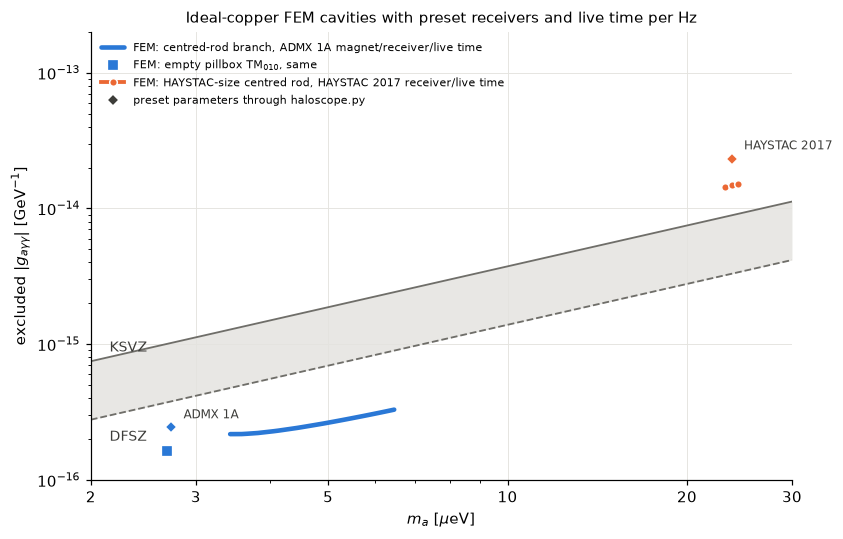

In [14]:
mm = np.geomspace(2, 30, 300)
gKl, gDl = hs.g_axion(mm * 1e-6, "KSVZ"), hs.g_axion(mm * 1e-6, "DFSZ")
fig, ax = plt.subplots(figsize=(7.8, 5.0))
ax.fill_between(mm, gDl, gKl, color="#d9d8d2", alpha=0.6, lw=0)
ax.plot(mm, gKl, color=GREY, lw=1.2); ax.plot(mm, gDl, color=GREY, lw=1.2, ls="--")
ax.text(2.15, gKl[0] * 1.18, "KSVZ", color="#3d3d3a", fontsize=9)
ax.text(2.15, gDl[0] * 0.70, "DFSZ", color="#3d3d3a", fontsize=9)
# ADMX-like: rod branch and empty pillbox
ax.plot(hs.freq_to_mass_eV(f_br) * 1e6, g_br, color=BLUE, lw=3, solid_capstyle="round",
        label="FEM: centred-rod branch, ADMX 1A magnet/receiver/live time")
ax.plot(m_eV * 1e6, g_pb, "s", ms=8, color=BLUE, mec="white", mew=1.5, label="FEM: empty pillbox TM$_{010}$, same")
# HAYSTAC-like
fh = np.array([h[0] for h in hay]); gh = np.array([h[1] for h in hay])
ax.plot(hs.freq_to_mass_eV(fh) * 1e6, gh, "-o", color=ORANGE, lw=2.5, ms=5, mec="white",
        label="FEM: HAYSTAC-size centred rod, HAYSTAC 2017 receiver/live time")
# preset model sensitivities
for name, col in (("ADMX_1A", BLUE), ("HAYSTAC_2017", ORANGE)):
    rr = hs.preset_limit(name); mp = hs.freq_to_mass_eV(rr["f_Hz"]) * 1e6
    ax.plot(mp, rr["g_GeV"], "D", ms=6, color=col, mec="white", mew=1.2, zorder=4)
    ax.annotate(name.replace("_", " "), (mp, rr["g_GeV"]), textcoords="offset points",
                xytext=(8, 6), fontsize=8, color="#3d3d3a")
ax.plot([], [], "D", ms=6, color="#3d3d3a", mec="white", label="preset parameters through haloscope.py")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(2, 30); ax.set_ylim(1e-16, 2e-13)
ax.set_xticks([2, 3, 5, 10, 20, 30]); ax.set_xticklabels(["2", "3", "5", "10", "20", "30"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel(r"$m_a$ [$\mu$eV]"); ax.set_ylabel(r"excluded $|g_{a\gamma\gamma}|$ [GeV$^{-1}$]")
ax.set_title("Ideal-copper FEM cavities with preset receivers and live time per Hz", fontsize=10)
ax.legend(fontsize=7.5, loc="upper left"); fig.tight_layout(); plt.show()

### COMSOL geometry export

The Java export contains geometry and named selections; it does not create a cavity eigenfrequency study.

We export the pillbox geometry as Java for use in COMSOL.

In [15]:
from axionfem import comsol
out = comsol.export_comsol(d, str(RUNS / "Pillbox.java"), format="java")
print(Path(out["file"]).name, {k: out[k] for k in ("class", "selections", "dimension", "approximations")})

Pillbox.java {'class': 'Pillbox', 'selections': ['air', 'cavity', 'wall'], 'dimension': 2, 'approximations': []}


The next step is [COMSOL export and import](../docs/guides/comsol.md).